Maximum likelihood estimation for an exponential RV (Victor Z, UW-Madison, 2014).

| Slides | Python | Meaning |
|---|---|---|
| $x_\omega$, $S$ | `x_omega`, `S` | data and sample size |
| $\beta$ | `beta` | grid of candidate scale values |
| $\log L(\beta)=-S\log\beta-\frac{1}{\beta}\sum_\omega x_\omega$ | `logL` | log likelihood |
| $\hat{\beta}=\hat{\mathbb{E}}_X$ | `beta_hat` | MLE |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon

np.random.seed(0)
S = 1000
x_omega = np.random.exponential(scale=2, size=S)

beta = np.linspace(0.1, 10, 200)
logL = -S * np.log(beta) - np.sum(x_omega) / beta
beta_hat = np.mean(x_omega)                # solves d logL / d beta = 0
print(f"beta_hat = {beta_hat:.3f}   (grid maximizer: {beta[np.argmax(logL)]:.3f})")

beta_hat = 2.007   (grid maximizer: 1.990)


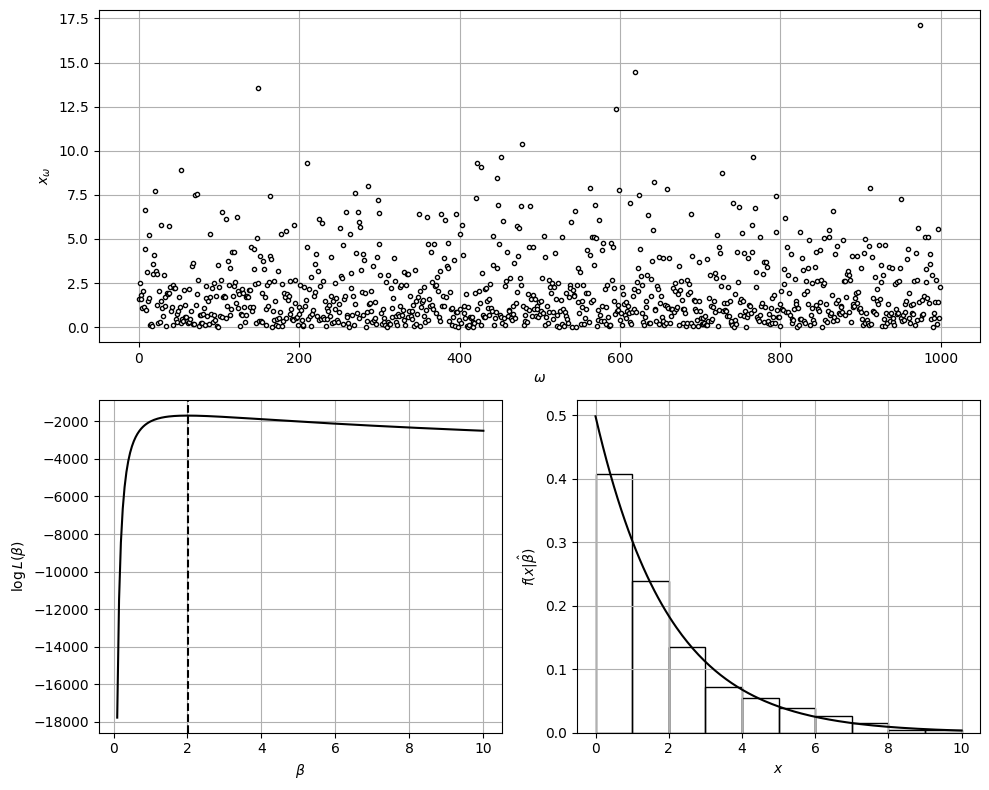

In [2]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(2, 1, 1)
ax.plot(x_omega, 'o', markerfacecolor='w', markeredgecolor='black', markersize=3)
ax.set_xlabel(r'$\omega$')
ax.set_ylabel(r'$x_\omega$')
ax = fig.add_subplot(2, 2, 3)
ax.plot(beta, logL, 'k-', linewidth=1.5)
ax.axvline(beta_hat, color='k', ls='--')
ax.set_xlabel(r'$\beta$')
ax.set_ylabel(r'$\log L(\beta)$')
ax = fig.add_subplot(2, 2, 4)
x = np.linspace(0, 10, 200)
ax.hist(x_omega, bins=np.arange(0, 11, 1), density=True, edgecolor='black', facecolor='none')
ax.plot(x, expon.pdf(x, scale=beta_hat), 'k-', linewidth=1.5)
ax.set_xlabel('$x$')
ax.set_ylabel(r'$f(x|\hat{\beta})$')
for a in fig.axes:
    a.grid(True)
plt.tight_layout()
plt.show()